# Simple CNN MT + Focal & Identity Loss (Scoliosis1K)

**Paper Reference:** Table 3, Row 1 (Accuracy: 45.5%, Sensitivity: 99.0%, Specificity: 27.0%).

**Paper Definition of Baseline CNN:**
> *"A basic model trained with cross-entropy loss, excluding horizontal pooling and BNNeck."*

**Implementation Choices to Match Paper:**
- **Backbone**: OpenGait `ResNet9` (channels `[64, 128, 256, 512]`, strides `[1, 2, 2, 1]`).
- **Temporal Aggregation**: Temporal Max Pooling (TP) over frames.
- **Head**: Global Average Pooling -> Linear(512, 256) -> Linear(256, 3). *No BNNeck, no scale=16.*
- **Loss**: Cross-Entropy only. Label smoothing 0.1 (OpenGait default).
- **Optimizer**: SGD, LR 0.1, Momentum 0.9, Weight Decay 0.0005. Milestones at 10k, 14k, 18k.
- **Data Pipeline**: `TripletSampler` (8 identities x 8 sequences) over the 1:1:8 split from `Scoliosis1K_118.json`.

**Expected Results Note**: The test set is heavily skewed toward Positive (419 out of 749). Blind guessing "Positive" yields ~56% accuracy. The paper's Baseline CNN achieving 45.5% is expected for a CE-only model without triplet identity supervision. It is completely normal if your reproduced accuracy lands in the 40-55% range.

In [1]:
import os
# Mencegah fragmentasi memori GPU agar tidak OOM
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import copy, json, pickle, random, time
from functools import lru_cache
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ==========================================
# 1. SETTINGS
# ==========================================
DATASET_ROOT = Path("/mnt/home/probation-01/kelompok8/OpenGait-ScoNet/datasets/Scoliosis1K-sil-pkl") 
PARTITION_JSON = Path("/mnt/home/probation-01/kelompok8/OpenGait-ScoNet/datasets/Scoliosis1K/Scoliosis1K_118.json")

LABELS = ["negative", "neutral", "positive"]
LABEL_TO_ID = {name: i for i, name in enumerate(LABELS)}
NUM_CLASSES = 3
N_FRAMES = 30

# Paper Hyperparameters
TOTAL_ITERS = 20000
MILESTONES = [10000, 14000, 18000]
TRAIN_LR = 0.01
IDS_PER_BATCH = 8
SEQS_PER_ID = 8
LABEL_SMOOTHING = 0.1

SEED = 0
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE} | PyTorch: {torch.__version__}")

# ==========================================
# 2. DATA LOADING & PREPROCESSING
# ==========================================
def load_pkl(path):
    with open(path, "rb") as f:
        seq = np.asarray(pickle.load(f))
    if seq.ndim == 4 and seq.shape[1] == 1:
        seq = seq[:, 0]
    elif seq.ndim == 4 and seq.shape[-1] == 1:
        seq = seq[..., 0]
    return seq

def cut_and_normalize(seq):
    cut = seq.shape[-1] // 64 * 10
    if cut > 0:
        seq = seq[..., cut:-cut]
    return seq.astype(np.float32) / 255.0

def random_clip(seq, n_frames=N_FRAMES):
    idx = np.random.choice(len(seq), n_frames, replace=len(seq) < n_frames)
    return seq[idx]

def train_clip(seq, n_frames=N_FRAMES):
    return cut_and_normalize(random_clip(seq, n_frames))

@lru_cache(maxsize=None)
def load_pkl_cached(path):
    return load_pkl(path)

def build_index(root, subject_ids):
    items = []
    for sid in subject_ids:
        folder = root / str(sid)
        if not folder.is_dir(): continue
        for pkl in sorted(folder.rglob("*.pkl")):
            names = [p.lower() for p in pkl.relative_to(root).parts[:-1]]
            class_id = next((LABEL_TO_ID[n] for n in names if n in LABEL_TO_ID), None)
            if class_id is not None:
                items.append((str(sid), class_id, pkl))
    return items

def make_triplet_batch_fn(items, ids_per_batch, seqs_per_id):
    """BALANCED SAMPLER: Mengambil subjek secara seimbang (Pos, Neu, Neg) per batch."""
    by_subject = {}
    for sid, class_id, path in items:
        by_subject.setdefault(sid, []).append((class_id, path))
    
    subjects_by_class = {0: [], 1: [], 2: []}
    for sid, seqs in by_subject.items():
        cid = seqs[0][0] 
        subjects_by_class[cid].append(sid)
        
    index = {sid: i for i, sid in enumerate(by_subject.keys())}

    def get_batch():
        clips, ids, classes = [], [], []
        # 3 Pos, 3 Neu, 2 Neg (Total 8 subjek = 64 gambar per iterasi)
        class_quota = {2: 3, 1: 3, 0: 2} 
        
        for cid, quota in class_quota.items():
            pool = subjects_by_class[cid]
            num_to_pick = min(quota, len(pool))
            
            if num_to_pick > 0:
                chosen_sids = random.sample(pool, num_to_pick)
                for sid in chosen_sids:
                    seq_pool = by_subject[sid]
                    if len(seq_pool) >= seqs_per_id:
                        picks = random.sample(seq_pool, seqs_per_id)
                    else:
                        picks = random.choices(seq_pool, k=seqs_per_id)
                        
                    for class_id, path in picks:
                        clips.append(train_clip(load_pkl_cached(path)))
                        ids.append(index[sid])
                        classes.append(class_id)
                        
        return np.stack(clips), np.array(ids), np.array(classes)
    return get_batch

Device: cuda | PyTorch: 2.15.0+cu132


In [2]:
# ==========================================
# 3. SIMPLE CNN ARCHITECTURE + MULTI-TASK (MT)
# ==========================================
import torch.nn.functional as F

class SimpleCNN_MT(nn.Module):
    def __init__(self, num_classes=3, num_ids=800, feat_dim=256):
        super().__init__()
        self.backbone = nn.Sequential(
            nn.Conv2d(1, 32, 3, 1, 1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, 1, 1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, 1, 1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        
        self.embedding = nn.Sequential(
            nn.Linear(128, feat_dim),
            nn.BatchNorm1d(feat_dim),
            nn.ReLU(),
            nn.Dropout(0.5)
        )
        
        # Task 1: Klasifikasi Skoliosis (3 kelas)
        self.classifier = nn.Linear(feat_dim, num_classes)
        
        # Task 2: Klasifikasi ID Subjek (Multi-Task)
        self.id_classifier = nn.Linear(feat_dim, num_ids) 

    def forward(self, sils):
        n, s, h, w = sils.shape
        x = sils.view(n * s, 1, h, w) 
        x = self.backbone(x) 
        x = x.view(n, s, -1) 
        
        # Temporal Max Pooling
        x = x.max(dim=1)[0] 
        
        embed = self.embedding(x)       # [n, 256]
        logits = self.classifier(embed) # [n, 3]
        id_logits = self.id_classifier(embed) # [n, num_ids]
        
        return embed.unsqueeze(-1), logits.unsqueeze(-1), id_logits

def init_weights(m):
    if isinstance(m, nn.Conv2d):
        nn.init.xavier_uniform_(m.weight)
    elif isinstance(m, nn.Linear):
        nn.init.xavier_uniform_(m.weight)
        if m.bias is not None: nn.init.zeros_(m.bias)
    elif isinstance(m, (nn.BatchNorm1d, nn.BatchNorm2d)) and m.affine:
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)

def make_model(num_ids):
    model = SimpleCNN_MT(num_ids=num_ids)
    model.apply(init_weights)
    return model.to(DEVICE)

In [3]:
# ==========================================
# 4. TRAINING LOOP (CE + FOCAL + MT IDENTITY)
# ==========================================
import torch.optim as optim

class FocalLoss(nn.Module):
    def __init__(self, alpha=1, gamma=2, label_smoothing=0.1):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.label_smoothing = label_smoothing

    def forward(self, logits, classes):
        ce_loss = F.cross_entropy(logits, classes, reduction='none', label_smoothing=self.label_smoothing)
        pt = torch.exp(-ce_loss)
        focal_loss = self.alpha * (1 - pt) ** self.gamma * ce_loss
        return focal_loss.mean()

def compute_loss(logits, id_logits, classes, ids):
    logits_flat = logits.mean(-1)
    
    # 1. Skoliosis CE Loss
    loss_ce = F.cross_entropy(logits_flat, classes, label_smoothing=0.1)
    
    # 2. Focal Loss (Bobot 0.5)
    focal = FocalLoss()
    loss_focal = focal(logits_flat, classes)
    
    # 3. Identity Loss (Multi-Task, Bobot 0.5)
    loss_id = F.cross_entropy(id_logits, ids)
    
    # Gabungkan
    total_loss = loss_ce + (0.5 * loss_focal) + (0.5 * loss_id)
    return total_loss, loss_ce, loss_id

def save_checkpoint(path, model, optimizer, scheduler, scaler, it, history):
    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                "iter": it, "history": history}, path)

def load_checkpoint(path, model, optimizer, scheduler, scaler):
    ckpt = torch.load(path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["optimizer"])
    scheduler.load_state_dict(ckpt["scheduler"])
    scaler.load_state_dict(ckpt["scaler"])
    print(f"Resumed from {path} at iteration {ckpt['iter']}")
    assert scheduler.last_epoch == ckpt["iter"], f"Scheduler mismatch!"
    return ckpt["history"], ckpt["iter"] + 1

def train(model, get_batch, iters, lr=0.01, milestones=(), log_every=100, amp=False, 
          label_smoothing=0.1, ckpt_path=None, save_every=5000, resume=False):
    amp = amp and DEVICE.type == "cuda"
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=list(milestones), gamma=0.1)
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    
    history = {"ce": [], "acc": [], "lr": [], "id_loss": []} 
    start_it = 1

    if resume and ckpt_path and Path(ckpt_path).is_file():
        history, start_it = load_checkpoint(ckpt_path, model, optimizer, scheduler, scaler)

    t0 = time.time()
    for it in range(start_it, iters + 1):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        
        sils, ids, classes = get_batch() 
        sils = torch.as_tensor(sils, dtype=torch.float32, device=DEVICE)
        classes = torch.as_tensor(classes, dtype=torch.long, device=DEVICE)
        ids = torch.as_tensor(ids, dtype=torch.long, device=DEVICE)

        accum_steps = 2
        chunk_size = 32
        total_loss_val = 0.0
        total_acc = 0.0
        total_id_val = 0.0
        
        for i in range(accum_steps):
            sils_chunk = sils[i*chunk_size : (i+1)*chunk_size]
            classes_chunk = classes[i*chunk_size : (i+1)*chunk_size]
            ids_chunk = ids[i*chunk_size : (i+1)*chunk_size]

            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp):
                embed, logits, id_logits = model(sils_chunk)
            
            logits = logits.float()
            id_logits = id_logits.float()
            
            loss, loss_ce_val, loss_id_val = compute_loss(logits, id_logits, classes_chunk, ids_chunk)
            loss = loss / accum_steps 
            scaler.scale(loss).backward()
            
            total_loss_val += loss.item() * accum_steps
            total_id_val += loss_id_val.item() / accum_steps
            total_acc += (logits.mean(-1).argmax(1) == classes_chunk).float().mean().item() / accum_steps
        
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        
        scale_before = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        scale_after = scaler.get_scale()
        
        history["lr"].append(optimizer.param_groups[0]['lr'])
        
        if scale_before == scale_after:
            scheduler.step()

        history["ce"].append(total_loss_val)
        history["acc"].append(total_acc)
        history["id_loss"].append(total_id_val)

        if it == start_it or it % log_every == 0 or it in milestones:
            elapsed = time.time() - t0
            eta = elapsed / (it - start_it + 1) * (iters - it)
            lr_now = optimizer.param_groups[0]['lr']
            print(f"iter {it:5d} | LR {lr_now:.2e} | Loss {total_loss_val:.4f} | ID {total_id_val:.4f} | acc {total_acc:.2f} | ETA {eta/60:.1f}m")
            
        if ckpt_path and save_every and (it % save_every == 0 or it == iters):
            save_checkpoint(ckpt_path, model, optimizer, scheduler, scaler, it, history)
    return history

In [4]:
# ==========================================
# 5. EVALUATION & VISUALIZATION
# ==========================================
@torch.no_grad()
def predict(model, seq_uint8, max_frames=720):
    model.eval()
    seq_uint8 = seq_uint8[:max_frames]
    x = torch.from_numpy(cut_and_normalize(seq_uint8)).unsqueeze(0).to(DEVICE)
    
    # PERBAIKAN: Ada 3 output (embed, logits, id_logits), abaikan sisanya
    _, logits, _ = model(x) 
    
    scores = logits.mean(-1)
    probs = torch.softmax(scores, dim=-1)[0].cpu().numpy()
    return int(probs.argmax()), probs

def confusion(model, items, max_frames=720):
    conf = np.zeros((3, 3), dtype=int)
    for _, class_id, path in items:
        pred, _ = predict(model, load_pkl_cached(path), max_frames)
        conf[class_id, pred] += 1
    return conf

def paper_metrics(conf):
    accuracy = conf.trace() / max(conf.sum(), 1)
    sensitivity = conf[0, 0] / max(conf[0].sum(), 1) 
    specificity = conf[1:, 1:].sum() / max(conf[1:].sum(), 1) 
    return accuracy, sensitivity, specificity

def plot_all(history, conf, acc, sen, spe):
    fig, axes = plt.subplots(1, 4, figsize=(24, 5))
    
    axes[0].plot(history["ce"], color='tab:blue', alpha=0.8)
    axes[0].set_title("Training Loss (Total)")
    axes[0].set_xlabel("Iteration")
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(history["acc"], color='tab:green', alpha=0.8)
    axes[1].set_title("Training Accuracy")
    axes[1].set_xlabel("Iteration")
    axes[1].set_ylim(0, 1.05)
    axes[1].grid(True, alpha=0.3)

    axes[2].plot(history["lr"], color='tab:red')
    axes[2].set_title("Learning Rate Schedule")
    axes[2].set_xlabel("Iteration")
    axes[2].set_yscale('log')
    axes[2].grid(True, alpha=0.3)

    im = axes[3].imshow(conf, cmap="Blues")
    for i in range(3):
        for j in range(3):
            axes[3].text(j, i, conf[i, j], ha="center", va="center", 
                         color="white" if conf[i, j] > conf.max() / 2 else "black")
    axes[3].set_xticks([0, 1, 2])
    axes[3].set_yticks([0, 1, 2])
    axes[3].set_xticklabels(LABELS)
    axes[3].set_yticklabels(LABELS)
    axes[3].set_xlabel("Predicted")
    axes[3].set_ylabel("True")
    axes[3].set_title(f"Confusion Matrix\nAcc: {acc:.1%} | Sen: {sen:.1%} | Spe: {spe:.1%}")
    fig.colorbar(im, ax=axes[3], fraction=0.046)
    
    plt.tight_layout()
    plt.show()

def evaluate(model, items, history):
    conf = confusion(model, items)
    acc, sen, spe = paper_metrics(conf)
    print(f"\nAccuracy: {acc:.1%} | Sensitivity: {sen:.1%} | Specificity: {spe:.1%}")
    plot_all(history, conf, acc, sen, spe)

Train sequences: 744 | Test sequences: 749 | Unique Train IDs: 744

Starting training: 20000 iters, 8x8 batch (split 2x32), LR 0.01
iter     1 | LR 1.00e-02 | Loss 10.6387 | ID 6.7127 | acc 0.39 | ETA 295.4m
iter   100 | LR 1.00e-02 | Loss 9.4818 | ID 6.7144 | acc 0.42 | ETA 38.1m
iter   200 | LR 1.00e-02 | Loss 8.9378 | ID 6.1168 | acc 0.47 | ETA 36.6m
iter   300 | LR 1.00e-02 | Loss 8.2227 | ID 5.5402 | acc 0.48 | ETA 36.1m
iter   400 | LR 1.00e-02 | Loss 7.5910 | ID 5.1857 | acc 0.53 | ETA 35.7m
iter   500 | LR 1.00e-02 | Loss 7.0583 | ID 5.0475 | acc 0.66 | ETA 35.2m
iter   600 | LR 1.00e-02 | Loss 7.0050 | ID 4.7799 | acc 0.58 | ETA 34.8m
iter   700 | LR 1.00e-02 | Loss 7.2482 | ID 4.9906 | acc 0.56 | ETA 34.6m
iter   800 | LR 1.00e-02 | Loss 7.0659 | ID 4.5832 | acc 0.58 | ETA 34.3m
iter   900 | LR 1.00e-02 | Loss 6.4190 | ID 4.1944 | acc 0.66 | ETA 34.0m
iter  1000 | LR 1.00e-02 | Loss 5.6756 | ID 4.1544 | acc 0.81 | ETA 33.8m
iter  1100 | LR 1.00e-02 | Loss 6.5373 | ID 4.6993 |

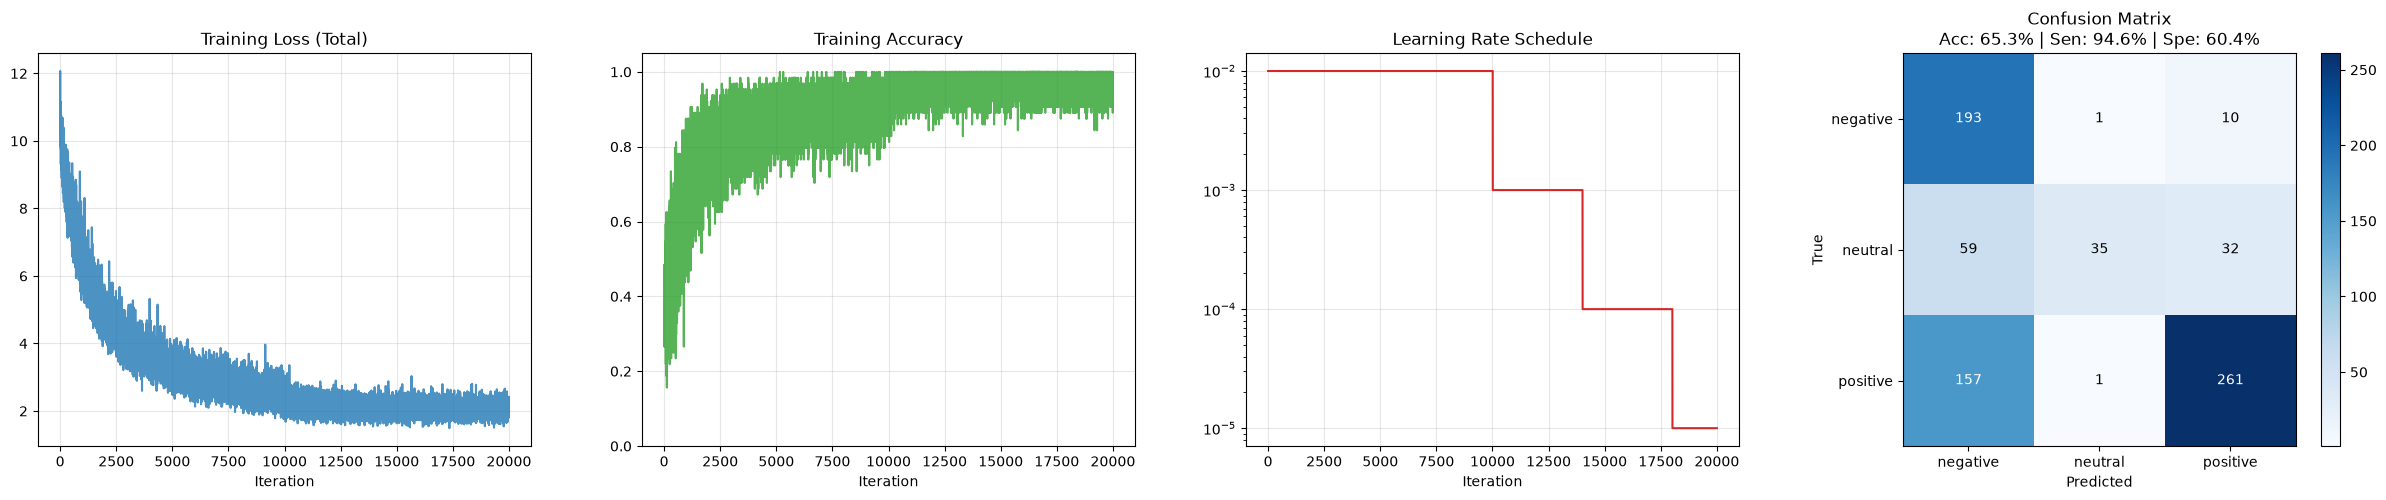

In [5]:
# ==========================================
# 6. EXECUTE TRAINING
# ==========================================
CKPT_PATH = "simplecnn_mt_focal_20000.pt"
RUN_FULL = True

if RUN_FULL:
    with open(PARTITION_JSON, "r", encoding="utf-8") as f:
        partition = json.load(f)
        
    train_items = build_index(DATASET_ROOT, partition["TRAIN_SET"])
    test_items = build_index(DATASET_ROOT, partition["TEST_SET"])
    
    # Hitung jumlah subjek unik di data training untuk Multi-Task
    num_train_ids = len(set([item[0] for item in train_items]))
    
    print(f"Train sequences: {len(train_items)} | Test sequences: {len(test_items)} | Unique Train IDs: {num_train_ids}")
    
    set_seed()
    model = make_model(num_train_ids) # Passing num_ids ke model
    get_batch = make_triplet_batch_fn(train_items, IDS_PER_BATCH, SEQS_PER_ID)
    
    print(f"\nStarting training: {TOTAL_ITERS} iters, 8x8 batch (split 2x32), LR {TRAIN_LR}")
    history = train(
        model, get_batch, iters=TOTAL_ITERS, lr=TRAIN_LR, 
        milestones=MILESTONES, log_every=100, amp=True, 
        label_smoothing=LABEL_SMOOTHING, ckpt_path=CKPT_PATH, save_every=5000, resume=False
    )
    
    print("\nTraining Complete. Evaluating...")
    evaluate(model, test_items, history)